In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

df = pd.read_csv("hotel_bookings.csv")
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [24]:
df = df.drop(columns=["reservation_status", "reservation_status_date", "company", "agent"])

print(df.shape)
print(df["is_canceled"].value_counts(normalize=True))

(119390, 28)
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


In [25]:
   df = df.drop_duplicates().reset_index(drop=True)
   print(df.shape)

(87110, 28)


In [26]:
print("Overall:", df["is_canceled"].mean())
print(df.groupby("hotel")["is_canceled"].mean())

Overall: 0.2727700608426128
hotel
City Hotel      0.298114
Resort Hotel    0.232936
Name: is_canceled, dtype: float64


In [27]:
print(df.groupby("deposit_type")["is_canceled"].mean())
print(df.groupby("customer_type")["is_canceled"].mean())

deposit_type
No Deposit    0.264845
Non Refund    0.945919
Refundable    0.242991
Name: is_canceled, dtype: float64
customer_type
Contract           0.162843
Group              0.099265
Transient          0.299808
Transient-Party    0.143116
Name: is_canceled, dtype: float64


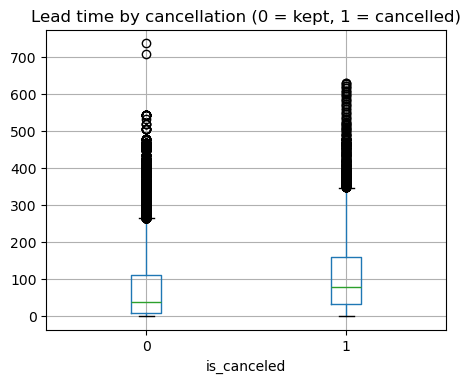

In [28]:
df.boxplot(column="lead_time", by="is_canceled", figsize=(5, 4))
plt.suptitle("")
plt.title("Lead time by cancellation (0 = kept, 1 = cancelled)")
plt.show()

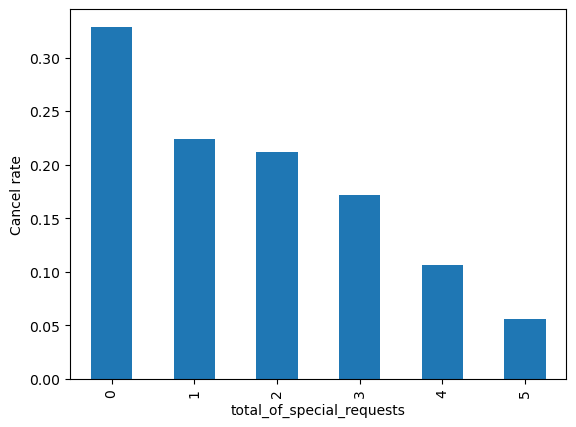

In [29]:
df.groupby("total_of_special_requests")["is_canceled"].mean().plot(kind="bar")
plt.ylabel("Cancel rate")
plt.show()

In [30]:
print(df.isna().sum()[df.isna().sum() > 0])

children      4
country     451
dtype: int64


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [32]:
X = df.drop(columns="is_canceled")
y = df["is_canceled"]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [34]:
print(X_train.shape, X_test.shape)

(69688, 27) (17422, 27)


In [35]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

print(len(num_cols), "numeric,", len(cat_cols), "categorical columns")
print(list(cat_cols))

17 numeric, 10 categorical columns
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


In [36]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                      min_frequency=100))]), cat_cols),
])

In [37]:
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000))
])

logreg.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  Index(['lead_time', 'arrival_date_year', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies',
       'is_repeated_guest', 'previous_ca...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=100))]),
                                                  Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type'],
      dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])

ROC-AUC: 0.843
              precision    recall  f1-score   support

           0       0.82      0.92      0.87     12670
           1       0.68      0.47      0.56      4752

    accuracy                           0.79     17422
   macro avg       0.75      0.69      0.71     17422
weighted avg       0.78      0.79      0.78     17422



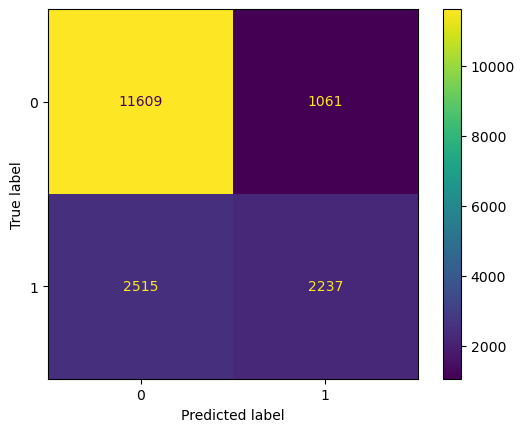

In [38]:
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay

proba = logreg.predict_proba(X_test)[:, 1]
pred = logreg.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

rf = Pipeline([
    ("prep", clone(preprocess)),
    ("model", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42))
])

rf.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  Index(['lead_time', 'arrival_date_year', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies',
       'is_repeated_guest', 'previous_ca...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=100))]),
                                                  Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

ROC-AUC: 0.898
              precision    recall  f1-score   support

           0       0.87      0.93      0.90     12670
           1       0.76      0.62      0.68      4752

    accuracy                           0.84     17422
   macro avg       0.81      0.77      0.79     17422
weighted avg       0.84      0.84      0.84     17422



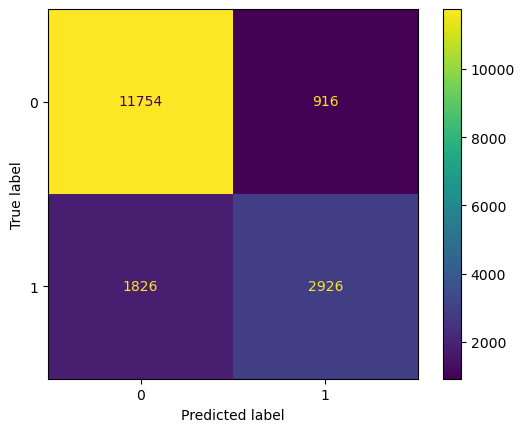

In [40]:
proba_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = rf.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, proba_rf), 3))
print(classification_report(y_test, pred_rf))
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf)
plt.show()

In [41]:
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)

top = imp.sort_values(ascending=False).head(15)
print(top)

num__lead_time                       0.135055
num__adr                             0.091078
num__arrival_date_day_of_month       0.067797
num__arrival_date_week_number        0.060024
num__total_of_special_requests       0.059141
num__stays_in_week_nights            0.047343
cat__country_PRT                     0.041536
num__stays_in_weekend_nights         0.030486
cat__market_segment_Online TA        0.029229
num__required_car_parking_spaces     0.028147
num__arrival_date_year               0.027354
num__booking_changes                 0.017773
num__adults                          0.016386
num__previous_cancellations          0.014981
cat__market_segment_Offline TA/TO    0.013271
dtype: float64


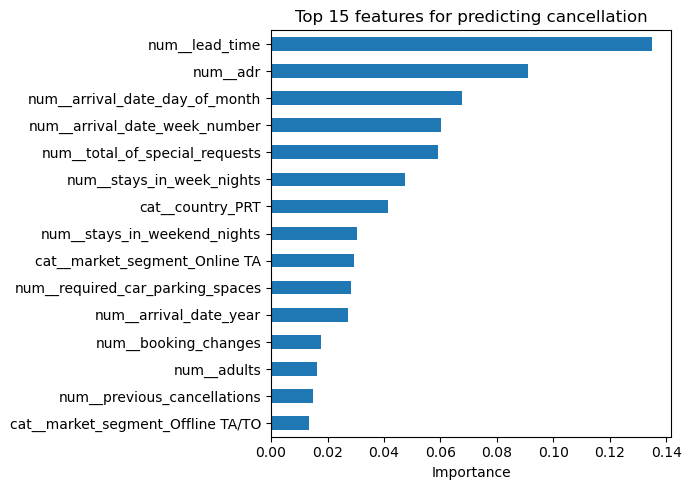

In [42]:
top.sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Top 15 features for predicting cancellation")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

lead_time                    0.135055
country                      0.121882
adr                          0.091078
arrival_date_day_of_month    0.067797
arrival_date_month           0.061148
arrival_date_week_number     0.060024
total_of_special_requests    0.059141
market_segment               0.051695
stays_in_week_nights         0.047343
assigned_room_type           0.032141
dtype: float64


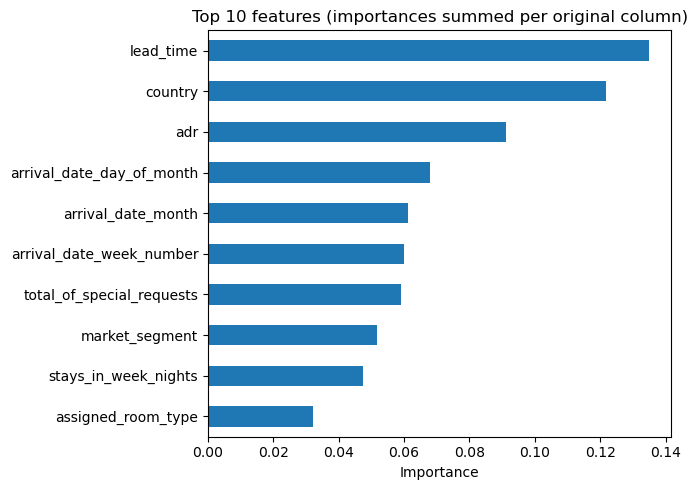

In [43]:
def original_col(name):
    if name.startswith("num__"):
        return name[len("num__"):]
    rest = name[len("cat__"):]
    for c in cat_cols:
        if rest.startswith(c + "_"):
            return c
    return rest

grouped = imp.groupby(imp.index.map(original_col)).sum().sort_values(ascending=False)
print(grouped.head(10))

grouped.head(10).sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("Top 10 features (importances summed per original column)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()